In [9]:
import pandas as pd
from collections import Counter
import numpy as np
import seaborn as sns
import bbi
import coolbox
from coolbox.api import *
import scipy.stats as stats
import matplotlib.pyplot as plt
import sys
sys.path.append('/scratch/gpfs/PRITYKIN/brendan/domino/python_modules')

plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

In [10]:
bdf_plot = pd.read_csv('../fig5_clustermap/finalized_nc14_cluster_metadata.csv', index_col=0)

sorted_boundaries_df = bdf_plot.copy()
sorted_boundaries_df = sorted_boundaries_df.sort_values(['chrom', 'start'])

all_pairs = []
for _, chrom_df in sorted_boundaries_df.groupby('chrom'):
    pairs = list(zip(chrom_df['cluster'].values[:-1], chrom_df['cluster'].values[1:]))
    # make (x,y) and (y,x) the same
    combined_pairs = [tuple(sorted(p)) for p in pairs]
    all_pairs.extend(combined_pairs)

pair_counts = Counter(all_pairs)

In [11]:
v = sorted_boundaries_df['cluster'].to_numpy()
chrom = sorted_boundaries_df['chrom'].to_numpy()

k = 30

mask = chrom[:-1] == chrom[1:]

a = v[:-1][mask]
b = v[1:][mask]

pairs = np.vstack([a, b]) 
pairs.sort(axis=0) # make first index in pair always be less than second

# obs is the pairs of boundaries (a, b) where a is cluster x and cluster 
obs = np.zeros((k, k), dtype=int)
np.add.at(obs, (pairs[0], pairs[1]), 1)

In [17]:
chrom_groups = [g.index.to_numpy() for _, g in sorted_boundaries_df.reset_index(drop=True).groupby('chrom')]

n_perm = 10000
null_counts = np.zeros((n_perm, k, k), dtype=int)

chrom = sorted_boundaries_df['chrom'].to_numpy()

mask = chrom[:-1] == chrom[1:]

np.random.seed(42)
# for 10000 permutations, we shuffle all indices randomly within each chrom
for p in range(n_perm):
    perm = v.copy()
    # shuffle within each chromosome
    for idx in chrom_groups:
        perm[idx] = np.random.permutation(perm[idx])

    # consecutive pairs
    a = perm[:-1][mask]
    b = perm[1:][mask]

    # merge (x,y) and (y,x)
    i = np.minimum(a, b)
    j = np.maximum(a, b)

    counts = np.zeros((k, k), dtype=int)
    np.add.at(counts, (i, j), 1)

    null_counts[p] = counts

In [18]:
# for each (i,j) compute the following:
# out of all the 10000 perms, what proportion of permutated counts surpassed the observed? 
pvals = ((null_counts >= obs).sum(axis=0) + 1) / (n_perm + 1)

In [19]:
import json
with open('../fig5_clustermap/cluster_annotations.json', 'r') as f:
    cluster2annotations = json.load(f)

In [20]:
labels = np.arange(0,30)
obs_df = pd.DataFrame(obs, index=labels, columns=labels)
pval_df = pd.DataFrame(pvals, index=labels, columns=labels)

from statsmodels.stats.multitest import multipletests

pvals_flat = np.diag(pval_df.to_numpy())

# Benjamini-Hochberg FDR correction
_, pvals_fdr, _, _ = multipletests(pvals_flat, method='fdr_bh')

# reshape back into k x k matrix
pval_df_fdr = pd.DataFrame(pvals_fdr)
pval_df_fdr.columns = ['padj']
pval_df_fdr.index = [cluster2annotations[str(c)] for c in pval_df_fdr.copy().index]

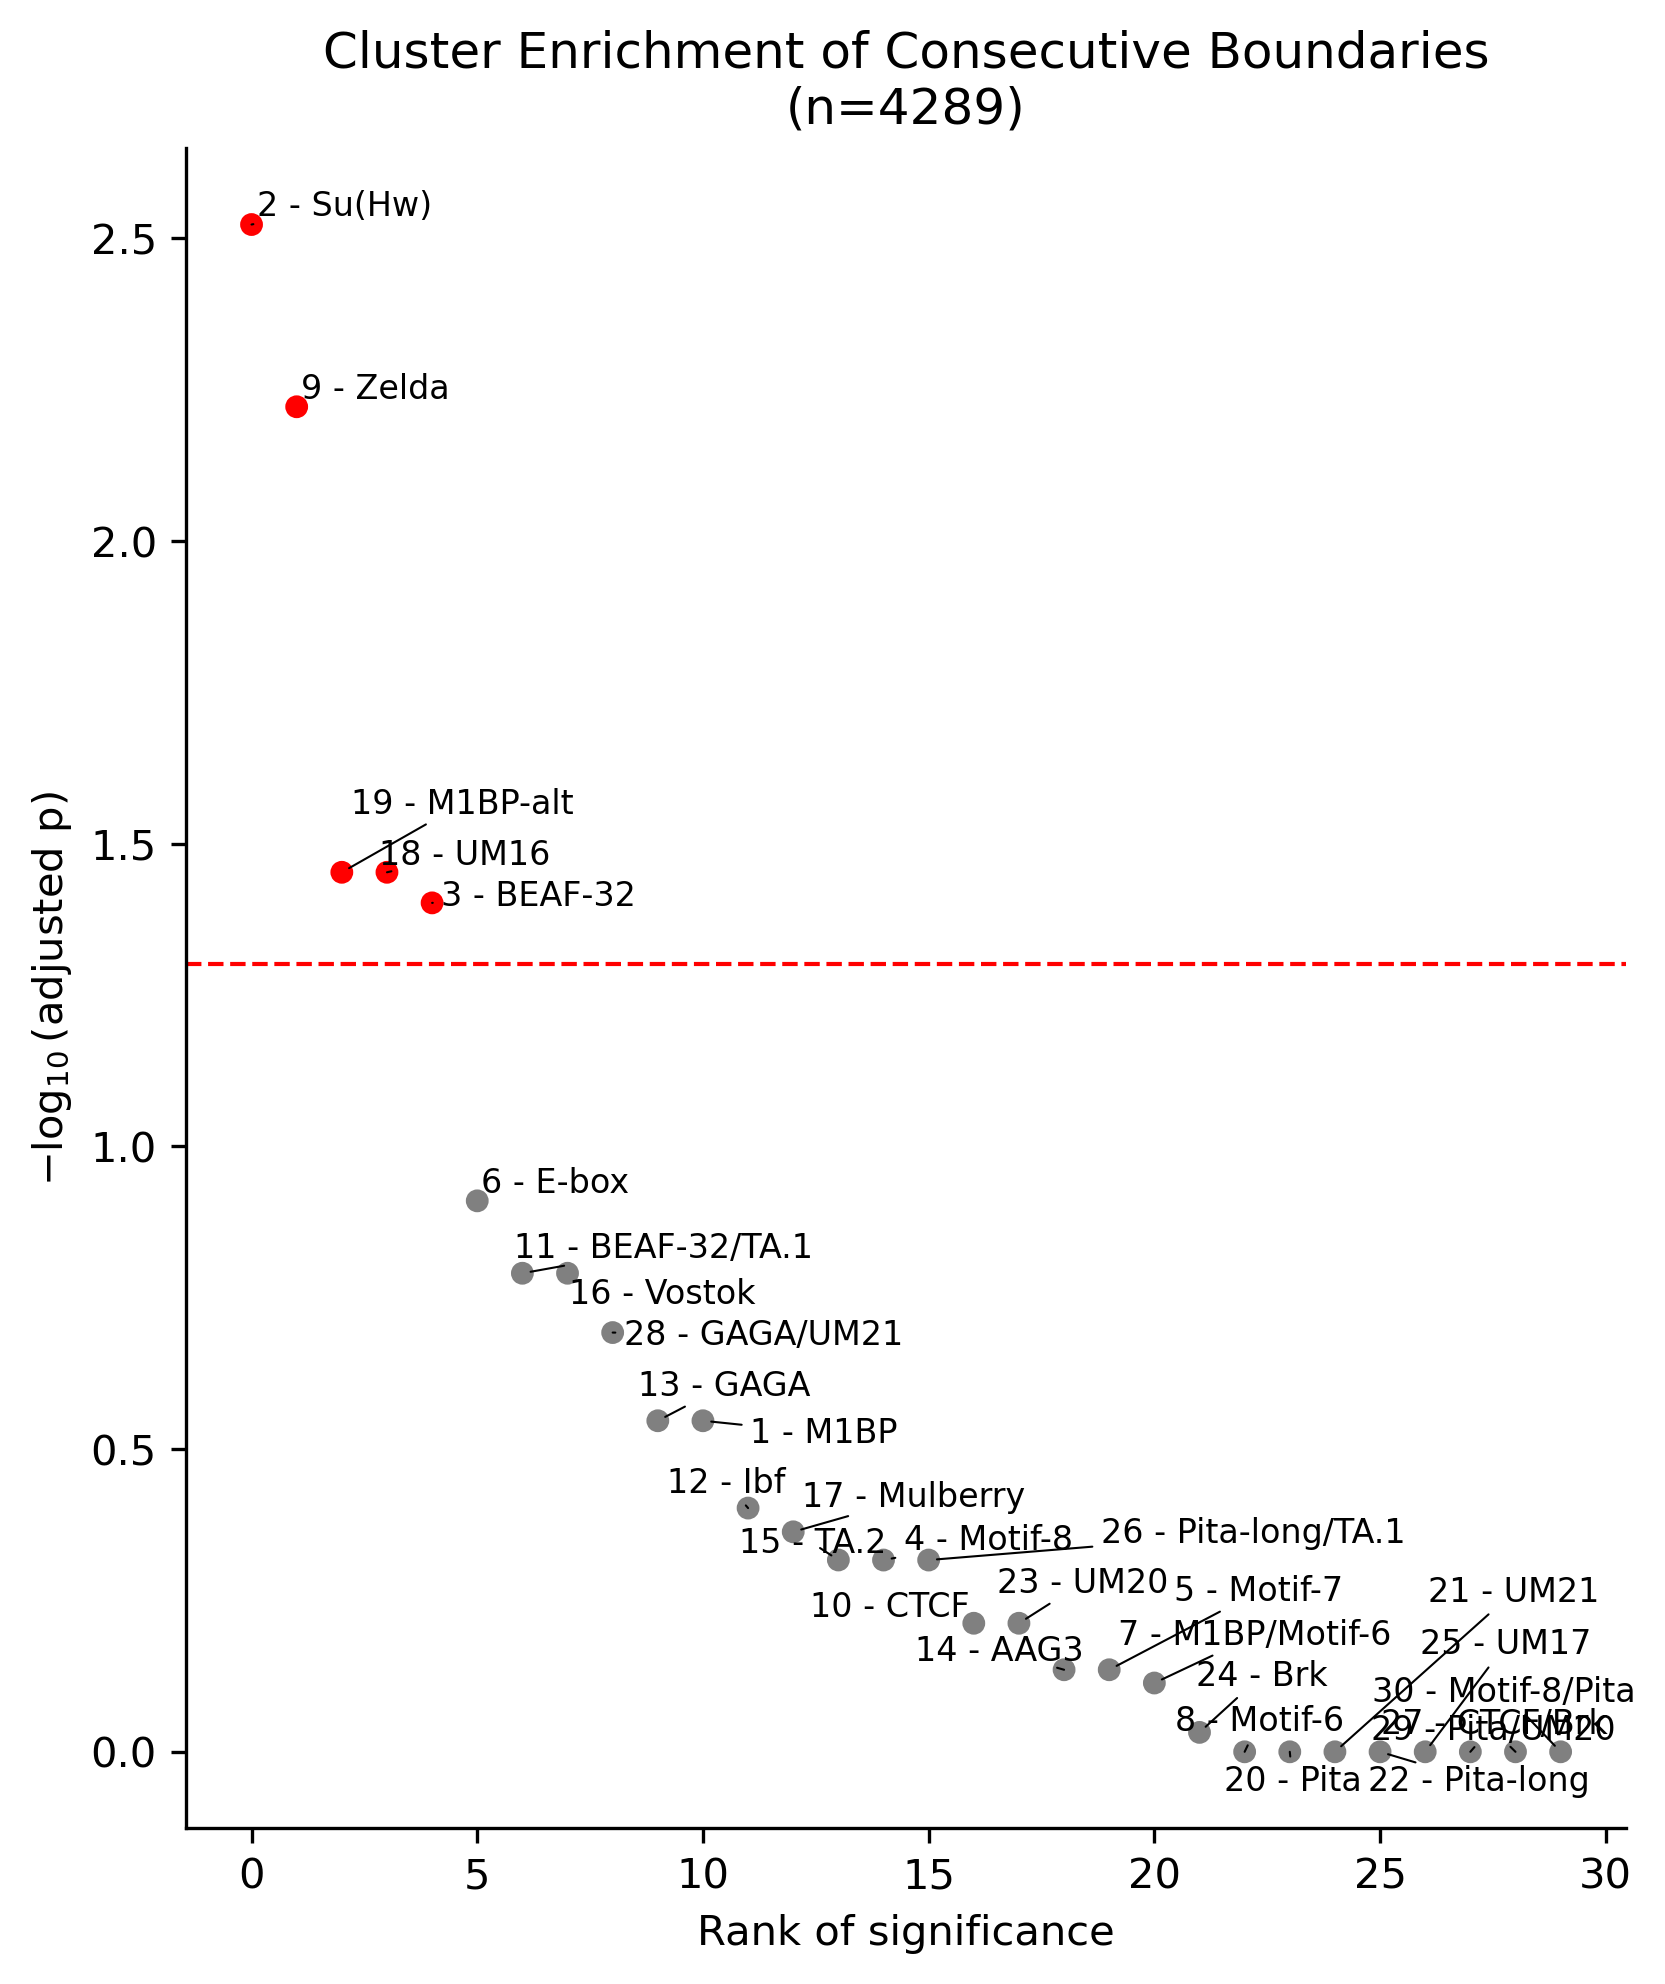

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from adjustText import adjust_text

padj_col = pval_df_fdr.columns[0]

plot_df = (
    pval_df_fdr.sort_values(padj_col)
      .copy()
)

plot_df['neglog10'] = -np.log10(plot_df[padj_col])

fig, ax = init_subplots_exact(1,1,dpi=300, x_ratios=[1.2], y_ratios=[1.4])

x = np.arange(len(plot_df))
y = plot_df['neglog10']

sig = plot_df[padj_col] < 0.05

ax.scatter(
    x,
    y,
    c=sig.map({True: 'red', False: 'gray'}),
    s=20
)

ax.axhline(
    -np.log10(0.05),
    linestyle='--',
    linewidth=1,
    c='red'
)

texts = []
for xi, yi, cluster in zip(x, y, plot_df.index):
    texts.append(
        ax.text(
            xi,
            yi,
            cluster,
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    explode_radius=2,
    arrowprops=dict(
        arrowstyle='-',
        lw=0.5
    )
)

ax.set_ylabel(r'$-\log_{10}(\mathrm{adjusted\ p})$')
ax.set_xlabel('Rank of significance')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.title(f'Cluster Enrichment of Consecutive Boundaries\n(n={len(bdf_plot)})')
plt.show()